# Lab Assignment 10: Fine-Tuning BERT-Family Models for Adverse Drug Effect Detection

**Student:** Muhammad Obaidullah (abdulsalam.m@northeastern.edu)  
**Course:** Applied NLP  
**Submission:** Upload `Lab_10.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

An adverse drug effect (ADE) is any harm caused by a medication at a normal therapeutic dose. Automatically detecting ADE mentions in clinical text — drug interaction reports, electronic health records, pharmacovigilance notes — is a high-value NLP task with direct patient safety implications. It is also a demanding test of pre-trained models: the vocabulary is highly specialized, the sentences are short but clinically dense, and the consequences of false negatives (missed adverse effects) are severe.

In this lab you will fine-tune two BERT-family models on the ADE Corpus and measure how much of the performance comes from pre-training versus model architecture. The two models share the same DistilBERT architecture but differ in pre-training domain: `distilbert-base-uncased` was pre-trained on general web text, while `allenai/scibert_scivocab_uncased` (SciBERT) was pre-trained on scientific publications including biomedical literature. The gap between them quantifies **domain shift** — the penalty for deploying a general-domain model on specialized text.

You will then profile both models for deployment and apply the fine-tune / prompt / train-from-scratch decision framework from the module to a realistic clinical scenario.

---

## Learning Objectives

1. Compare BERT's masked language model pre-training against a domain-adapted variant, assessing what each pre-training regime biases the model toward
2. Fine-tune two pre-trained models for ADE detection and evaluate them against a non-pre-trained baseline, interpreting the performance delta
3. Justify the choice between fine-tuning, prompting, and training from scratch for a given task by analyzing task data size, domain shift, and resource constraints
4. Implement efficient batch inference for both models and diagnose latency and memory bottlenecks against a realistic deployment SLA

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1 — Pre-training objectives and domain shift | 18 | Autograded (12) + Manual (6) |
| Part 2 — Fine-tuning and baseline comparison | 28 | Autograded (22) + Manual (6) |
| Part 3 — Deployment decision analysis | 14 | Autograded (8) + Manual (6) |
| Part 4 — Batch inference profiling | 26 | Autograded (20) + Manual (6) |
| Code quality | 14 | Manual |
| **Total** | **100** | |

### Manual grading rubric

**Reflections (6 pts each):**  
Full credit requires a specific, evidence-grounded claim connected to a concrete mechanism, using precise NLP terminology.

**Code quality (14 pts):**

| Criterion | Points |
|---|---|
| Docstrings and inline comments | 4 |
| Function design | 4 |
| Defensive coding | 3 |
| Code clarity and naming | 2 |
| Avoiding redundancy | 1 |

---

## Setup

**Runtime recommendation:** GPU strongly recommended for Part 2 fine-tuning.  
In Google Colab: *Runtime → Change runtime type → T4 GPU.*

In [1]:
# Setup — run this cell first every session.

import subprocess, sys

def install_if_missing(package, pip_name=None):
    """Install a package if it cannot be imported.

    Args:
        package  (str): Importable module name.
        pip_name (str): pip install name if different.
    """
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip",
                               "install", pip_name or package, "-q"])

for pkg, pip in [
    ("transformers", "transformers>=4.46.0"),  # Fix: Trainer(processing_class=...) needs >= 4.46
    ("datasets",     "datasets>=2.19.0"),
    ("torch",        None),
    ("sklearn",      "scikit-learn"),
    ("numpy",        None),
    ("matplotlib",   None),
    ("evaluate",     None),
    ("accelerate",   "accelerate>=0.26.0"),  # Fix: Trainer raises ImportError without accelerate
]:
    install_if_missing(pkg, pip)

import torch
import numpy as np
import matplotlib.pyplot as plt
import time, warnings
import datasets, transformers
warnings.filterwarnings('ignore')
# Keep the saved output readable: no download/progress bars or load reports.
datasets.disable_progress_bars()
transformers.logging.disable_progress_bar()
transformers.logging.set_verbosity_error()
datasets.logging.set_verbosity_error()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED   = 42
torch.manual_seed(SEED); np.random.seed(SEED)

print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
else:
    print("No GPU — fine-tuning in Part 2 will be slow on CPU.")
print("Setup complete.")

Device: cuda
GPU: NVIDIA RTX A6000
Memory: 50.9 GB
Setup complete.


---

## Part 1 — Pre-Training Objectives and Domain Shift (18 points)

### Why domain matters for biomedical NLP

`distilbert-base-uncased` was pre-trained on BookCorpus and English Wikipedia — general text where biomedical terms are rare, multi-word, and often appear in lay contexts. `allenai/scibert_scivocab_uncased` (SciBERT) was pre-trained on 1.14 million scientific papers from Semantic Scholar, roughly 18% biomedical and 82% computer science. Its vocabulary was built from scratch on scientific text, so terms like *thrombocytopenia* or *acetaminophen* appear as whole tokens rather than fragmented subwords.

This difference in pre-training distribution is called **domain shift**. It manifests in two measurable ways:
1. **Tokenization:** rare biomedical terms fragment into more subword pieces in general-BERT than in SciBERT
2. **Masked predictions:** fill-mask predictions on biomedical sentences differ between the two models, reflecting what each learned to associate with domain vocabulary

### 1.1 — Load tokenizers and probe fill-mask

In [2]:
from transformers import pipeline, AutoTokenizer

# Load tokenizers for both models
tok_distil = AutoTokenizer.from_pretrained("distilbert-base-uncased")
tok_scibert = AutoTokenizer.from_pretrained("allenai/scibert_scivocab_uncased")

print(f"DistilBERT vocab size: {tok_distil.vocab_size:,}")
print(f"SciBERT vocab size:    {tok_scibert.vocab_size:,}")
print()
print("Note: SciBERT has a vocabulary built from scratch on scientific text.")
print("DistilBERT shares BERT-base's general-corpus vocabulary.")

DistilBERT vocab size: 30,522
SciBERT vocab size:    31,090

Note: SciBERT has a vocabulary built from scratch on scientific text.
DistilBERT shares BERT-base's general-corpus vocabulary.


In [3]:
def show_tokenization(text, tokenizer, label):
    """Display tokenized subwords for a text string.

    Args:
        text      (str):       Input sentence.
        tokenizer:             HuggingFace tokenizer.
        label     (str):       Model label for display.

    Returns:
        list[str]: Subword tokens (no special tokens).
    """
    tokens = tokenizer.tokenize(text)
    print(f"{label} ({len(tokens)} tokens):")
    print(f"  {tokens}")
    return tokens


# Biomedical terms that general-BERT fragments heavily
ade_terms = [
    "thrombocytopenia",
    "acetaminophen",
    "hepatotoxicity",
    "rhabdomyolysis",
    "agranulocytosis",
]

print("Tokenization comparison — biomedical terms")
print("=" * 65)
print(f"{'Term':<22} {'DistilBERT':>20}  {'SciBERT':>20}")
print("-" * 65)
for term in ade_terms:
    d_toks = tok_distil.tokenize(term)
    s_toks = tok_scibert.tokenize(term)
    print(f"{term:<22} {str(len(d_toks))+' pieces':>20}  "
          f"{str(len(s_toks))+' pieces':>20}")

print()
# Detailed view for one sentence
ade_sentence = "Severe hepatotoxicity was observed following acetaminophen overdose."
print(f"Full sentence: '{ade_sentence}'")
print()
d_sent_toks = show_tokenization(ade_sentence, tok_distil, "DistilBERT")
print()
s_sent_toks = show_tokenization(ade_sentence, tok_scibert, "SciBERT")

# Named output variables for autograder
distilbert_token_count = len(d_sent_toks)
scibert_token_count    = len(s_sent_toks)
print(f"\nDistilBERT token count: {distilbert_token_count}")
print(f"SciBERT token count:    {scibert_token_count}")

Tokenization comparison — biomedical terms
Term                             DistilBERT               SciBERT
-----------------------------------------------------------------
thrombocytopenia                   6 pieces              2 pieces
acetaminophen                      5 pieces              3 pieces
hepatotoxicity                     6 pieces              2 pieces
rhabdomyolysis                     5 pieces              4 pieces
agranulocytosis                    5 pieces              5 pieces

Full sentence: 'Severe hepatotoxicity was observed following acetaminophen overdose.'

DistilBERT (17 tokens):
  ['severe', 'he', '##pa', '##to', '##to', '##xi', '##city', 'was', 'observed', 'following', 'ace', '##tam', '##ino', '##ph', '##en', 'overdose', '.']

SciBERT (12 tokens):
  ['severe', 'hepat', '##otoxicity', 'was', 'observed', 'following', 'acet', '##amino', '##phen', 'over', '##dose', '.']

DistilBERT token count: 17
SciBERT token count:    12


### 1.2 — Fill-mask predictions: what each model learned

In [4]:
# Fix: load each fill-mask pipeline once; the provided function rebuilt both on every call.
fill_distil  = pipeline("fill-mask", model="distilbert-base-uncased")
fill_scibert = pipeline("fill-mask", model="allenai/scibert_scivocab_uncased")


def compare_fill_mask(sentence_with_mask, top_k=5):
    """Compare fill-mask predictions between DistilBERT and SciBERT.

    Uses the fill_distil and fill_scibert pipelines loaded above.

    Args:
        sentence_with_mask (str): Sentence containing '[MASK]' or '<mask>'.
        top_k              (int): Number of top predictions to show.

    Returns:
        dict: {'distilbert': [...], 'scibert': [...]} lists of (token, score).
    """
    # DistilBERT uses [MASK], SciBERT uses [MASK] too
    d_results = fill_distil(sentence_with_mask, top_k=top_k)
    s_results = fill_scibert(sentence_with_mask, top_k=top_k)

    print(f"Input: {sentence_with_mask}")
    print(f"\n{'Rank':<6} {'DistilBERT':>20} {'Score':>8}  |  "
          f"{'SciBERT':>20} {'Score':>8}")
    print("-" * 70)
    for i, (d, s) in enumerate(zip(d_results, s_results), 1):
        print(f"  {i:<4} {d['token_str'].strip():>20} {d['score']:>8.4f}  |  "
              f"{s['token_str'].strip():>20} {s['score']:>8.4f}")

    return {
        'distilbert': [(r['token_str'].strip(), r['score']) for r in d_results],
        'scibert':    [(r['token_str'].strip(), r['score']) for r in s_results],
    }


print("Fill-mask comparison on clinical sentences")
print("=" * 70)
print()

# Test 1: Drug-adverse effect relationship
mask_results_1 = compare_fill_mask(
    "The patient developed [MASK] after taking ibuprofen for three weeks.")
print()

# Test 2: Clinical assertion vocabulary
mask_results_2 = compare_fill_mask(
    "Warfarin therapy was discontinued due to [MASK] complications.")
print()

# Test 3: Dose-response language
mask_results_3 = compare_fill_mask(
    "Hepatotoxicity risk increases with [MASK] doses of acetaminophen.")

Fill-mask comparison on clinical sentences

Input: The patient developed [MASK] after taking ibuprofen for three weeks.

Rank             DistilBERT    Score  |               SciBERT    Score
----------------------------------------------------------------------
  1               pneumonia   0.3931  |              diarrhea   0.1048
  2                symptoms   0.0932  |          constipation   0.0568
  3                 amnesia   0.0615  |              headache   0.0480
  4           complications   0.0479  |                  pain   0.0422
  5                seizures   0.0458  |                nausea   0.0319

Input: Warfarin therapy was discontinued due to [MASK] complications.

Rank             DistilBERT    Score  |               SciBERT    Score
----------------------------------------------------------------------
  1                   liver   0.0988  |              bleeding   0.6832
  2                 cardiac   0.0717  |           hemorrhagic   0.0267
  3                  healt

### 1.3 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The tokenization comparison shows that DistilBERT fragments biomedical terms more heavily than SciBERT. Explain the concrete downstream consequence of this fragmentation for a sequence classification task like ADE detection. Think about what the model "sees" as a representation of the word *hepatotoxicity* in each case, and what that means for the classification head's ability to learn from that term.

**Question B:** Looking at the fill-mask predictions, identify one position where SciBERT's top prediction is more clinically appropriate than DistilBERT's. Explain why the pre-training corpus difference would cause this gap — specifically, what does SciBERT's pre-training data contain that BERT's does not, and how does MLM training encode that information into the model weights?

**Your reflection:**

**A.** DistilBERT's general WordPiece vocabulary splits *hepatotoxicity* into six pieces, *he ##pa ##to ##to ##xi ##city*, where SciBERT needs two, *hepat ##otoxicity*, and the probe sentence grows from 12 to 17 tokens. Pieces such as *he*, the pronoun's token, and *##city* are shared with unrelated words, so their input embeddings carry no hepatic or toxic meaning, and the encoder must compose the concept across its layers before it reaches the [CLS] vector the classification head reads (J&M, *Words and Tokens*). The head therefore gets a weaker, noisier signal from rare adverse-effect terms, since DistilBERT must largely learn each composition during fine-tuning from the few training sentences containing the term, whereas SciBERT starts from a liver stem and a toxicity suffix.

**B.** For *Warfarin therapy was discontinued due to [MASK] complications.*, SciBERT puts 0.6832 on *bleeding*, the principal hazard of anticoagulation, while DistilBERT's top choice is the generic *liver* at 0.0988. SciBERT was pre-trained on full-text Semantic Scholar papers, 82% biomedical per Beltagy et al. (2019), where warfarin and hemorrhage co-occur often, whereas DistilBERT learned from BookCorpus and Wikipedia, partly by matching BERT's MLM outputs (Sanh et al., 2019). MLM minimizes the cross-entropy of each masked token over the vocabulary given its bidirectional context, so gradient updates shift the embeddings and the attention and feed-forward parameters until the predicted distribution approximates the corpus's co-occurrence statistics, and a drug–effect pairing that recurs in pre-training becomes a peaked prediction (J&M, *Masked Language Models*).

---

## Part 2 — Fine-Tuning and Baseline Comparison (28 points)

### The ADE Corpus

The ADE Corpus v2 (Gurulingappa et al., 2012) contains 23,516 sentences from medical case reports, each labeled as:
- **ADE (1):** the sentence reports an adverse effect of a drug
- **Non-ADE (0):** the sentence does not report an adverse effect

This is a binary sequence classification task on short, clinically dense sentences. With ~23k labeled examples it is firmly in the fine-tuning regime — enough data to adapt a pre-trained model but not enough to train from scratch competitively.

You will compare three models:

| Model | Initialization | Training data |
|---|---|---|
| TF-IDF + Logistic Regression | — | ADE labeled set |
| DistilBERT (fine-tuned) | General pre-training | ADE labeled set |
| SciBERT (fine-tuned) | Scientific pre-training | ADE labeled set |

The F1 gap between DistilBERT and SciBERT quantifies the **domain shift penalty**.

### 2.1 — Load the ADE Corpus

In [5]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split
import numpy as np

print("Loading ADE Corpus v2...")
# ade_corpus_v2 sentence classification split:
# label 0 = non-ADE, label 1 = ADE
# Fix: huggingface_hub now rejects ids without a namespace; this is the same dataset's Hub id.
ade_raw = load_dataset("ade-benchmark-corpus/ade_corpus_v2", "Ade_corpus_v2_classification")

# ADE corpus is published as a single split — we create train/val/test
# Fix: datasets >= 4 returns lazy Column objects; materialize plain lists.
texts  = list(ade_raw["train"]["text"])
labels = list(ade_raw["train"]["label"])

# Stratified splits: 70% train, 15% val, 15% test
X_trainval, X_test, y_trainval, y_test = train_test_split(
    texts, labels, test_size=0.15, stratify=labels, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.15/0.85,
    stratify=y_trainval, random_state=SEED)

print(f"Train:      {len(X_train):,} examples")
print(f"Validation: {len(X_val):,} examples")
print(f"Test:       {len(X_test):,} examples")
print(f"\nLabel distribution (test):")
from collections import Counter
for lbl, cnt in sorted(Counter(y_test).items()):
    print(f"  {'ADE' if lbl==1 else 'Non-ADE'} ({lbl}): {cnt:,} "
          f"({cnt/len(y_test):.1%})")
print()
print("Sample ADE sentence:")
ade_idx = next(i for i,l in enumerate(y_train) if l==1)  # Fix: enumerate labels, not texts
print(f"  {X_train[ade_idx]}")
print("Sample Non-ADE sentence:")
non_idx = next(i for i,l in enumerate(y_train) if l==0)  # Fix: enumerate labels, not texts
print(f"  {X_train[non_idx]}")

Loading ADE Corpus v2...


Train:      16,460 examples
Validation: 3,528 examples
Test:       3,528 examples

Label distribution (test):
  Non-ADE (0): 2,505 (71.0%)
  ADE (1): 1,023 (29.0%)

Sample ADE sentence:
  Prolonged prostate-specific antigen response in flutamide withdrawal syndrome despite disease progression.
Sample Non-ADE sentence:
  However, these patients may be admitted to an intensive care unit (ICU) with complications of Wolff Parkinson White (WPW) syndrome; for example post cardiopulmonary arrest or WPW as a co-morbidity.


### 2.2 — Baseline: TF-IDF + Logistic Regression

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

LABEL_NAMES = ['Non-ADE', 'ADE']   # list index = label id


def check_aligned(items, labels, name):
    """Raise ValueError if items is empty or its length differs from labels.

    Args:
        items  (Sized): Texts or a tokenized dataset.
        labels (Sized): Labels, one per item.
        name   (str):   Argument name used in the error message.
    """
    if len(items) == 0:
        raise ValueError(f"{name} is empty")
    if len(items) != len(labels):
        raise ValueError(f"{name} has {len(items)} items but {len(labels)} labels")


def train_tfidf_baseline(X_train, y_train, X_test, y_test):
    """Train TF-IDF + Logistic Regression and return test metrics.

    Args:
        X_train, X_test (list[str]): Text examples.
        y_train, y_test (list[int]): Binary labels (0=Non-ADE, 1=ADE).

    Returns:
        dict: {'accuracy': float, 'f1': float, 'predictions': list[int]}
              where f1 is the binary F1 of the ADE class (label 1).
    """
    check_aligned(X_train, y_train, "X_train")
    check_aligned(X_test, y_test, "X_test")
    vectorizer = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2),
                                 sublinear_tf=True)
    classifier = LogisticRegression(max_iter=1000, C=5.0, random_state=SEED)
    # Vocabulary and IDF weights come from the training split only.
    classifier.fit(vectorizer.fit_transform(X_train), y_train)
    predictions = classifier.predict(vectorizer.transform(X_test))
    return {
        'accuracy':    float(accuracy_score(y_test, predictions)),
        'f1':          float(f1_score(y_test, predictions, pos_label=1)),
        'predictions': predictions.tolist(),
    }


tfidf_results = train_tfidf_baseline(X_train, y_train, X_test, y_test)

# Named output variable
tfidf_f1       = tfidf_results['f1']
tfidf_accuracy = tfidf_results['accuracy']

print(f"TF-IDF + Logistic Regression")
print(f"  Accuracy: {tfidf_accuracy:.4f}")
print(f"  F1 (ADE): {tfidf_f1:.4f}")
print()
print(classification_report(y_test, tfidf_results['predictions'],
                              target_names=['Non-ADE', 'ADE'], digits=4))

TF-IDF + Logistic Regression
  Accuracy: 0.9025
  F1 (ADE): 0.8273

              precision    recall  f1-score   support

     Non-ADE     0.9222    0.9421    0.9321      2505
         ADE     0.8504    0.8055    0.8273      1023

    accuracy                         0.9025      3528
   macro avg     0.8863    0.8738    0.8797      3528
weighted avg     0.9014    0.9025    0.9017      3528



### 2.3 — Tokenize for BERT-family models

In [7]:
from datasets import Dataset as HFDataset
from transformers import DataCollatorWithPadding

def prepare_hf_dataset(texts, labels, tokenizer, max_length=128):
    """Tokenize a list of texts and return a HuggingFace Dataset.

    Uses truncation only (no padding — DataCollatorWithPadding handles
    per-batch dynamic padding during training and inference).

    Args:
        texts      (list[str]):   Input sentences.
        labels     (list[int]):   Binary labels.
        tokenizer:                HuggingFace tokenizer.
        max_length (int):         Maximum token length.

    Returns:
        datasets.Dataset: Tokenized dataset with 'label' column.
    """
    check_aligned(texts, labels, "texts")
    encodings = tokenizer(list(texts), truncation=True, max_length=max_length)
    # Token columns plus labels only; the raw text column is not kept.
    return HFDataset.from_dict(dict(encodings, label=list(labels)))


# Build datasets for both models (different tokenizers!)
# DistilBERT
train_ds_distil = prepare_hf_dataset(X_train, y_train, tok_distil)
val_ds_distil   = prepare_hf_dataset(X_val,   y_val,   tok_distil)
test_ds_distil  = prepare_hf_dataset(X_test,  y_test,  tok_distil)

# SciBERT
train_ds_scibert = prepare_hf_dataset(X_train, y_train, tok_scibert)
val_ds_scibert   = prepare_hf_dataset(X_val,   y_val,   tok_scibert)
test_ds_scibert  = prepare_hf_dataset(X_test,  y_test,  tok_scibert)

print(f"DistilBERT train features: {train_ds_distil.features}")
print(f"SciBERT train features:    {train_ds_scibert.features}")

DistilBERT train features: {'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8')), 'label': Value('int64')}
SciBERT train features:    {'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8')), 'label': Value('int64')}


### 2.4 — Fine-tuning helper

In [8]:
import numpy as np
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    """Compute accuracy and F1 from Trainer eval predictions.

    Args:
        eval_pred: NamedTuple with (predictions, label_ids).

    Returns:
        dict: {'accuracy': float, 'f1': float}
    """
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1":       f1_score(labels, preds, average="binary"),
    }


def fine_tune_model(model_name, train_ds, val_ds, tokenizer,
                    output_dir, n_epochs=3, lr=2e-5, batch_size=16):
    """Fine-tune a sequence classification model using the Hugging Face Trainer.

    Evaluates on val_ds after every epoch and reloads the epoch with the
    best validation F1 at the end. Training runs in fp32.

    Args:
        model_name  (str):         HuggingFace model checkpoint name.
        train_ds:                  Tokenized HuggingFace training Dataset.
        val_ds:                    Tokenized HuggingFace validation Dataset.
        tokenizer:                 Corresponding tokenizer.
        output_dir  (str):         Directory for checkpoints.
        n_epochs    (int):         Number of training epochs.
        lr          (float):       Adam learning rate.
        batch_size  (int):         Per-device batch size.

    Returns:
        tuple: (trainer, model) — trained Trainer and model objects.
    """
    if len(train_ds) == 0 or len(val_ds) == 0:
        raise ValueError("train_ds and val_ds must be non-empty")
    if n_epochs < 1 or batch_size < 1:
        raise ValueError(f"n_epochs and batch_size must be >= 1, "
                         f"got {n_epochs} and {batch_size}")

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=n_epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,             # on disk: the latest checkpoint (+ the best, if older)
        load_best_model_at_end=True,
        metric_for_best_model="f1",     # higher is better
        logging_strategy="epoch",       # one train-loss line per epoch
        disable_tqdm=True,
        report_to="none",
        seed=SEED,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        processing_class=tokenizer,     # replaces the removed tokenizer= argument
        data_collator=DataCollatorWithPadding(tokenizer),   # pads each batch to its longest
        compute_metrics=compute_metrics,
    )
    trainer.train()
    # trainer.model now holds the best epoch's weights.
    return trainer, trainer.model

In [9]:
# Fine-tune DistilBERT
print("Fine-tuning DistilBERT (distilbert-base-uncased)...")
t0 = time.perf_counter()
trainer_distil, model_distil = fine_tune_model(
    model_name  = "distilbert-base-uncased",
    train_ds    = train_ds_distil,
    val_ds      = val_ds_distil,
    tokenizer   = tok_distil,
    output_dir  = "./results_distilbert",
)
distilbert_train_time = time.perf_counter() - t0
print(f"DistilBERT training time: {distilbert_train_time/60:.1f} min")

Fine-tuning DistilBERT (distilbert-base-uncased)...


{'loss': '0.25', 'grad_norm': '15.62', 'learning_rate': '1.334e-05', 'epoch': '1'}


{'eval_loss': '0.1776', 'eval_accuracy': '0.9382', 'eval_f1': '0.892', 'eval_runtime': '1.848', 'eval_samples_per_second': '1910', 'eval_steps_per_second': '119.6', 'epoch': '1'}


{'loss': '0.1314', 'grad_norm': '0.2376', 'learning_rate': '6.673e-06', 'epoch': '2'}


{'eval_loss': '0.2128', 'eval_accuracy': '0.9413', 'eval_f1': '0.902', 'eval_runtime': '1.868', 'eval_samples_per_second': '1888', 'eval_steps_per_second': '118.3', 'epoch': '2'}


{'loss': '0.07813', 'grad_norm': '0.07632', 'learning_rate': '6.479e-09', 'epoch': '3'}


{'eval_loss': '0.2353', 'eval_accuracy': '0.9467', 'eval_f1': '0.9084', 'eval_runtime': '1.87', 'eval_samples_per_second': '1887', 'eval_steps_per_second': '118.2', 'epoch': '3'}


{'train_runtime': '90.77', 'train_samples_per_second': '544', 'train_steps_per_second': '34.01', 'train_loss': '0.1532', 'epoch': '3'}


DistilBERT training time: 1.5 min


In [10]:
# Fine-tune SciBERT
print("Fine-tuning SciBERT (allenai/scibert_scivocab_uncased)...")
t0 = time.perf_counter()
trainer_scibert, model_scibert = fine_tune_model(
    model_name  = "allenai/scibert_scivocab_uncased",
    train_ds    = train_ds_scibert,
    val_ds      = val_ds_scibert,
    tokenizer   = tok_scibert,
    output_dir  = "./results_scibert",
)
scibert_train_time = time.perf_counter() - t0
print(f"SciBERT training time: {scibert_train_time/60:.1f} min")

Fine-tuning SciBERT (allenai/scibert_scivocab_uncased)...


{'loss': '0.219', 'grad_norm': '9.427', 'learning_rate': '1.334e-05', 'epoch': '1'}


{'eval_loss': '0.2163', 'eval_accuracy': '0.9368', 'eval_f1': '0.8974', 'eval_runtime': '2.948', 'eval_samples_per_second': '1197', 'eval_steps_per_second': '74.97', 'epoch': '1'}


{'loss': '0.1022', 'grad_norm': '0.1619', 'learning_rate': '6.673e-06', 'epoch': '2'}


{'eval_loss': '0.1783', 'eval_accuracy': '0.9535', 'eval_f1': '0.9219', 'eval_runtime': '2.945', 'eval_samples_per_second': '1198', 'eval_steps_per_second': '75.04', 'epoch': '2'}


{'loss': '0.0489', 'grad_norm': '0.3448', 'learning_rate': '6.479e-09', 'epoch': '3'}


{'eval_loss': '0.2151', 'eval_accuracy': '0.9572', 'eval_f1': '0.9268', 'eval_runtime': '2.945', 'eval_samples_per_second': '1198', 'eval_steps_per_second': '75.04', 'epoch': '3'}


{'train_runtime': '154.3', 'train_samples_per_second': '320.1', 'train_steps_per_second': '20.01', 'train_loss': '0.1234', 'epoch': '3'}


SciBERT training time: 2.6 min


### 2.5 — Evaluate and compare

In [11]:
def evaluate_model(trainer, test_ds, test_labels, model_label):
    """Evaluate a trained Trainer on the test set and print results.

    Args:
        trainer     (Trainer):     Trained Hugging Face Trainer.
        test_ds:                   Tokenized test Dataset.
        test_labels (list[int]):   True labels for test set.
        model_label (str):         Display name.

    Returns:
        dict: {'accuracy': float, 'f1': float, 'predictions': np.ndarray}
              where f1 is the binary F1 of the ADE class (label 1).
    """
    check_aligned(test_ds, test_labels, "test_ds")
    logits = trainer.predict(test_ds).predictions      # (n_examples, 2), in test_ds order
    predictions = np.argmax(logits, axis=-1)
    accuracy = float(accuracy_score(test_labels, predictions))
    f1 = float(f1_score(test_labels, predictions, pos_label=1))

    print(f"{model_label} — test accuracy {accuracy:.4f}, F1 (ADE) {f1:.4f}")
    print(classification_report(test_labels, predictions,
                                target_names=LABEL_NAMES, digits=4))
    return {'accuracy': accuracy, 'f1': f1, 'predictions': predictions}


distilbert_results = evaluate_model(
    trainer_distil, test_ds_distil, y_test, "DistilBERT (fine-tuned)")
scibert_results    = evaluate_model(
    trainer_scibert, test_ds_scibert, y_test, "SciBERT (fine-tuned)")

# Named output variables
distilbert_f1 = distilbert_results['f1']
scibert_f1    = scibert_results['f1']
domain_shift_delta = scibert_f1 - distilbert_f1

print("\n" + "=" * 65)
print(f"{'Model':<35} {'Accuracy':>10}  {'F1 (ADE)':>10}")
print("=" * 65)
print(f"{'TF-IDF + LR':<35} {tfidf_accuracy:>10.4f}  {tfidf_f1:>10.4f}")
print(f"{'DistilBERT (fine-tuned)':<35} "
      f"{distilbert_results['accuracy']:>10.4f}  {distilbert_f1:>10.4f}")
print(f"{'SciBERT (fine-tuned)':<35} "
      f"{scibert_results['accuracy']:>10.4f}  {scibert_f1:>10.4f}")
print("=" * 65)
print(f"\nDomain shift penalty (SciBERT − DistilBERT F1): "
      f"{'+'if domain_shift_delta>0 else ''}{domain_shift_delta:.4f}")
print()
print("The domain shift delta quantifies how much the general-corpus pre-training")
print("hurts performance relative to scientifically pre-trained weights.")

DistilBERT (fine-tuned) — test accuracy 0.9473, F1 (ADE) 0.9111
              precision    recall  f1-score   support

     Non-ADE     0.9715    0.9537    0.9625      2505
         ADE     0.8915    0.9316    0.9111      1023

    accuracy                         0.9473      3528
   macro avg     0.9315    0.9426    0.9368      3528
weighted avg     0.9483    0.9473    0.9476      3528



SciBERT (fine-tuned) — test accuracy 0.9563, F1 (ADE) 0.9266
              precision    recall  f1-score   support

     Non-ADE     0.9792    0.9589    0.9689      2505
         ADE     0.9042    0.9501    0.9266      1023

    accuracy                         0.9563      3528
   macro avg     0.9417    0.9545    0.9478      3528
weighted avg     0.9575    0.9563    0.9567      3528


Model                                 Accuracy    F1 (ADE)
TF-IDF + LR                             0.9025      0.8273
DistilBERT (fine-tuned)                 0.9473      0.9111
SciBERT (fine-tuned)                    0.9563      0.9266

Domain shift penalty (SciBERT − DistilBERT F1): +0.0155

The domain shift delta quantifies how much the general-corpus pre-training
hurts performance relative to scientifically pre-trained weights.


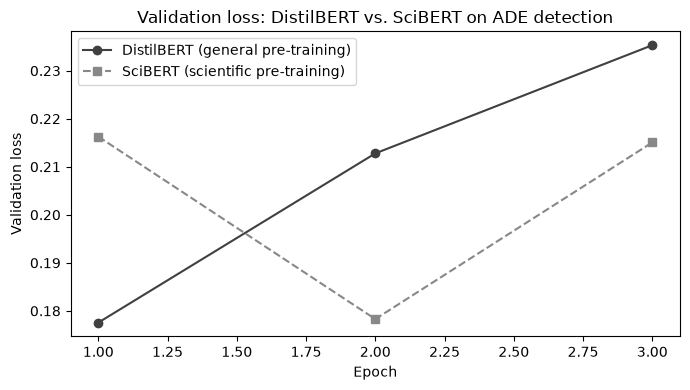

In [12]:
# [RUN] — training curves

def extract_loss_curve(trainer):
    """Extract (epoch, eval_loss) pairs from Trainer log history.

    Args:
        trainer (Trainer): Trained Hugging Face Trainer.

    Returns:
        tuple[list[float], list[float]]: Epochs and validation losses,
        one entry per evaluation.
    """
    epochs, losses = [], []
    for entry in trainer.state.log_history:
        if "eval_loss" in entry:
            epochs.append(entry["epoch"])
            losses.append(entry["eval_loss"])
    return epochs, losses

d_epochs, d_losses = extract_loss_curve(trainer_distil)
s_epochs, s_losses = extract_loss_curve(trainer_scibert)

fig_curves, ax = plt.subplots(figsize=(7, 4))
ax.plot(d_epochs, d_losses, "o-",  color='#404040',
        label="DistilBERT (general pre-training)")
ax.plot(s_epochs, s_losses, "s--", color='#888888',
        label="SciBERT (scientific pre-training)")
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss")
ax.set_title("Validation loss: DistilBERT vs. SciBERT on ADE detection")
ax.legend(); plt.tight_layout(); plt.show()

### 2.6 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The F1 gap between SciBERT and DistilBERT is the domain shift delta. Connect this to the tokenization difference you observed in Part 1: does the fragmentation of biomedical terms in DistilBERT's vocabulary provide a plausible *mechanism* for the performance gap? Explain why a model that represents *hepatotoxicity* as four subword pieces might be at a disadvantage compared to one that represents it as a single token, given that the task requires detecting whether a sentence reports a drug-related harm.

**Question B:** Both models significantly outperform TF-IDF + Logistic Regression. Identify the specific capability that pre-trained contextual representations provide that TF-IDF cannot — name one concrete type of sentence that the BERT-family models should handle correctly that TF-IDF likely gets wrong, and explain why TF-IDF fails on it.

**Your reflection:**

**A.** Yes, though the measured split is six pieces against two, not four against one (*he ##pa ##to ##to ##xi ##city* versus *hepat ##otoxicity*). Detecting harm usually turns on such effect terms, and SciBERT's units already carry liver and toxicity meaning from biomedical pre-training, while DistilBERT must largely learn to compose it from fragments during fine-tuning, which fits SciBERT's higher ADE recall (0.9501 against 0.9316). The +0.0155 F1 delta is not a controlled measure of domain shift: Part 5.1 shows 6 layers and 66,955,010 parameters for DistilBERT against 12 and 109,920,002 for SciBERT, so it confounds domain with depth and capacity and is an upper bound on the domain effect.

**B.** TF-IDF + LR sums fixed weights over tf-idf-weighted unigrams and bigrams, so an n-gram counts the same wherever it occurs and no cue can scope over distant words, whereas self-attention conditions every token on the whole sentence (J&M, *Transformers and Pretraining*). In *There is no consensus on the treatment of ticlopidine-induced marrow aplasia.* (ADE; SciBERT right, TF-IDF wrong), *no* attaches to *consensus*, not the aplasia, yet *no* and *treatment of* carry the same weights wherever they occur, while a contextual encoder can bind *ticlopidine-induced* to *marrow aplasia*. Negation does not drive the gain: only 11 of SciBERT's 275 wins contain a negation cue, below the test-set rate of 277 of 3,528 (Part 5.4), so the gain is broad, consistent with better representations of rare terms such as *Isotretinoin teratogenicity.*

---

## Part 3 — Deployment Decision Analysis (14 points)

### 3.1 — Decision framework

The module introduced a framework for choosing between three approaches when deploying NLP for a new task:

- **Fine-tuning:** adapt a pre-trained model using labeled task data. Best when: moderate labeled data (hundreds to tens of thousands), domain shift is manageable, GPU resources available for training.
- **Prompting:** use an instruction-tuned model with zero or few examples in the prompt, no weight updates. Best when: labeled data is very scarce (<50 examples), task is general-domain, latency is flexible.
- **Training from scratch:** build and train a model entirely from labeled data. Best when: the domain is so specialized that no pre-trained model transfers, data is abundant (millions of examples), and long-term maintenance justifies the cost.

Apply this framework to the two deployment scenarios below. For each, state your recommended approach, identify the two or three factors from the framework that most strongly determine your choice, and justify why the alternatives are less appropriate.

**Note on prompting:** Prompting with instruction-tuned LLMs is covered in depth in Module 12. For this analysis, you should reason about prompting as a theoretical option using the framework criteria above — you do not need to implement it here.

In [13]:
# [RUN] — scenario summary (no code to write here)

scenarios = {
    "Scenario A — Hospital ADE surveillance system": {
        "task":              "Classify sentences in physician notes as ADE / Non-ADE",
        "labeled_examples":  2_500,
        "domain":            "Biomedical / clinical notes",
        "latency_SLA_ms":    150,
        "infra":             "CPU-only inference servers; no GPU budget",
        "update_frequency":  "Quarterly retraining on new labeled batches",
    },
    "Scenario B — Rare disease case report tagger": {
        "task":              "Tag sentences describing adverse events in case reports",
        "labeled_examples":  45,
        "domain":            "Ultra-specialized rare-disease literature",
        "latency_SLA_ms":    5_000,
        "infra":             "Research compute cluster (GPU available)",
        "update_frequency":  "Ad hoc, infrequent",
    },
}

print("Deployment scenarios")
print("=" * 70)
for name, props in scenarios.items():
    print(f"\n{name}")
    print("-" * 60)
    for k, v in props.items():
        print(f"  {k:<22}: {v}")

Deployment scenarios

Scenario A — Hospital ADE surveillance system
------------------------------------------------------------
  task                  : Classify sentences in physician notes as ADE / Non-ADE
  labeled_examples      : 2500
  domain                : Biomedical / clinical notes
  latency_SLA_ms        : 150
  infra                 : CPU-only inference servers; no GPU budget
  update_frequency      : Quarterly retraining on new labeled batches

Scenario B — Rare disease case report tagger
------------------------------------------------------------
  task                  : Tag sentences describing adverse events in case reports
  labeled_examples      : 45
  domain                : Ultra-specialized rare-disease literature
  latency_SLA_ms        : 5000
  infra                 : Research compute cluster (GPU available)
  update_frequency      : Ad hoc, infrequent


### 3.2 — Scenario A analysis

**Scenario A:** Hospital ADE surveillance system — 2,500 labeled examples, biomedical domain, 150ms latency SLA, CPU-only inference.

Apply the framework. Your answer should address:
- Which approach do you recommend, and why?
- Which two factors most strongly drive this choice?
- Why is prompting less suitable here, even though it requires no labeled data?
- Why is training from scratch less suitable despite the domain specificity?

**Scenario A recommendation:** Fine-tune a pre-trained biomedical encoder such as SciBERT and serve it on the CPU servers.

- **Labeled data (decisive):** 2,500 examples sit inside the framework's fine-tuning range (hundreds to tens of thousands).
- **CPU-only, 150 ms SLA (decisive):** on CPU with 4 threads the single-sentence p95 was 25.5 ms for DistilBERT and 48.1 ms for SciBERT, both passing (Part 5.3), pending a load test on the hospital's servers (3.4).
- **GPU for training:** one fine-tuning run on 16,460 sentences took 1.5 min (DistilBERT) and 2.6 min (SciBERT) on one GPU, so quarterly retraining on 2,500 needs minutes of rented GPU time; the CPU servers only serve inference.
- **Domain shift (picks the encoder):** SciBERT beat DistilBERT by +0.0155 F1, and with only 2,500 sentences the advantage may be larger (expected, not measured).

**Why not prompting:** an instruction-tuned LLM for zero-shot classification is orders of magnitude larger than a BERT encoder, so on CPU-only servers it would miss the 150 ms SLA; it also leaves the 2,500 labels unused.

**Why not from scratch:** the framework requires millions of examples and a domain no pre-trained model transfers to; 2,500 is orders of magnitude short, and biomedical encoders already transfer (SciBERT F1 0.9266).

### 3.3 — Scenario B analysis

**Scenario B:** Rare disease case report tagger — 45 labeled examples, ultra-specialized domain, 5,000ms latency SLA, GPU available.

Apply the framework. Your answer should address:
- Which approach do you recommend, and why?
- How does the labeled data size (45 examples) change the analysis relative to Scenario A?
- If an instruction-tuned LLM were available with strong biomedical knowledge, would that change your recommendation? Why or why not?

**Scenario B recommendation:** Prompting: give an instruction-tuned LLM on the GPU cluster a task description and a few labeled demonstrations, and keep the rest of the 45 examples as a held-out set to evaluate the prompt.

- **Labeled data (decisive):** 45 examples fall below the framework's 50-example threshold. Relative to Scenario A's 2,500, this moves the task out of the fine-tuning regime: updating a 109,920,002-parameter encoder (SciBERT, Part 5.1) on 45 sentences would overfit, and the handful left for validation could not reliably select a checkpoint or detect overfitting.
- **Latency and infrastructure:** a 5,000 ms SLA and an available GPU absorb LLM inference latency, and ad hoc, infrequent use needs no retraining pipeline.
- **From scratch (ruled out):** 45 examples cannot train a model from random initialization.

**Strong biomedical LLM:** this reinforces rather than changes the recommendation. The framework's main argument against prompting here is domain shift, since prompting suits general-domain tasks, and an LLM with biomedical knowledge from pre-training and instruction tuning narrows exactly that gap (J&M, *Post-training*). I would still score it on the held-out examples and move to fine-tuning once labeled data reaches the hundreds.

In [14]:
# Named output variables — set these after completing your analysis above

# 'finetune', 'prompting', or 'scratch'
scenario_a_recommendation = 'finetune'
scenario_b_recommendation = 'prompting'

print(f"Scenario A recommendation: {scenario_a_recommendation}")
print(f"Scenario B recommendation: {scenario_b_recommendation}")

Scenario A recommendation: finetune
Scenario B recommendation: prompting


### 3.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer in 4–6 sentences total.

Scenario A has a 150ms latency SLA and CPU-only inference. You observed in your fine-tuning experiment that both DistilBERT and SciBERT are transformer models with similar parameter counts. Explain why latency is a *deployment* concern distinct from fine-tuning accuracy: even if SciBERT achieves higher F1, there are conditions under which you might choose a lower-F1 model for production. Name at least one architectural or operational factor — beyond raw accuracy — that would drive that choice, and explain how you would measure whether a model meets the SLA before committing to deployment.

**Your reflection:**

F1 belongs to the weights, while latency belongs to the weights running on specific hardware under specific load, so the more accurate model can still miss the SLA in production. The two models are also not similar in size: Part 5.1 shows 6 layers and 66,955,010 parameters for DistilBERT against 12 layers and 109,920,002 for SciBERT, and because encoder layers run sequentially at the same hidden width, SciBERT does about twice the encoder compute per token. The GPU latencies in 4.3 (3.1 and 5.6 ms) do not transfer to Scenario A's CPU-only servers, where with 4 threads the single-sentence p95 is 25.5 ms for DistilBERT and 48.1 ms for SciBERT (Part 5.3), 48.1 / 25.5 ≈ 1.9 times slower. Both pass in isolation, but under concurrent traffic each request gets fewer cores and waits in a queue, so if peak load pushes SciBERT's tail past 150 ms while DistilBERT keeps headroom, giving up 0.0155 F1 (0.9111 against 0.9266) costs less than missed deadlines or extra servers. Before committing, I would load-test each model on the target server with production thread settings and expected concurrency, timing tokenization plus inference on a realistic length mix that includes the long tail, and accept it only if p95 and p99 stay under 150 ms with margin.

---

## Part 4 — Batch Inference Profiling (26 points)

You will profile both fine-tuned models across a range of batch sizes and measure:
- **Throughput** (sentences per second) — the rate metric for high-volume pipelines
- **Per-batch latency** (ms) — the rate metric for latency-sensitive pipelines
- **GPU memory** (MB) — the constraint that limits maximum batch size
- **Dynamic vs. fixed padding** efficiency — the optimization that reduces wasted compute

Finally, you will diagnose whether each model meets the 150ms single-document SLA from Scenario A.

### 4.1 — DataLoader-based batch inference

In [15]:
from torch.utils.data import DataLoader, Dataset as TorchDataset
from transformers import DataCollatorWithPadding

class ADETextDataset(TorchDataset):
    """Tokenized ADE sentence dataset for inference profiling.

    Args:
        texts      (list[str]):   Input sentences.
        tokenizer:                HuggingFace tokenizer.
        max_length (int):         Truncation length.
        padding    (bool | str):  False (default) leaves sequences unpadded so
                                  DataCollatorWithPadding pads per batch;
                                  "max_length" pads every sequence to
                                  max_length (fixed padding, 4.2).
    """

    # padding is an added argument (default keeps the stub's behaviour); 4.2 passes "max_length".
    def __init__(self, texts, tokenizer, max_length=128, padding=False):
        """Tokenize every text once; arguments are described in the class docstring."""
        if len(texts) == 0:
            raise ValueError("texts is empty")
        self.encodings = tokenizer(list(texts), truncation=True,
                                   padding=padding, max_length=max_length)

    def __len__(self):
        """Return the number of sentences."""
        return len(self.encodings["input_ids"])

    def __getitem__(self, idx):
        """Return one tokenized sentence.

        Args:
            idx (int): Sentence index.

        Returns:
            dict[str, torch.Tensor]: 1-D LongTensors keyed by tokenizer output
            name (input_ids, attention_mask, and token_type_ids when the
            tokenizer returns them).
        """
        return {key: torch.tensor(values[idx]) for key, values in self.encodings.items()}


def run_batch_inference(model, dataloader, device):
    """Run full inference on a DataLoader and return all predictions.

    Args:
        model      (nn.Module):  Model in eval mode.
        dataloader (DataLoader): Inference batches.
        device     (torch.device): Device to run on (the model is moved
                                   there if it is not already).

    Returns:
        np.ndarray: Predicted class indices, shape (n_examples,).
    """
    if len(dataloader) == 0:
        raise ValueError("dataloader yields no batches")
    model.to(device).eval()                       # dropout off
    predictions = []
    with torch.inference_mode():                  # no autograd graph or version counters
        for batch in dataloader:
            inputs = {key: tensor.to(device) for key, tensor in batch.items()}
            predictions.append(model(**inputs).logits.argmax(dim=-1).cpu())
    return torch.cat(predictions).numpy()

In [16]:
def make_loader(dataset, tokenizer, batch_size):
    """Build an in-order DataLoader that pads each batch to its longest sequence.

    Args:
        dataset    (ADETextDataset): Tokenized sentences.
        tokenizer:                   Tokenizer whose pad token the collator uses.
        batch_size (int):            Sentences per batch, a positive int.

    Returns:
        DataLoader: shuffle=False, so every run sees the same batches.
    """
    if isinstance(batch_size, bool) or not isinstance(batch_size, int) or batch_size < 1:
        raise ValueError(f"batch_size must be a positive int, got {batch_size!r}")
    return DataLoader(dataset, batch_size=batch_size, shuffle=False,
                      collate_fn=DataCollatorWithPadding(tokenizer))


def time_inference_pass(model, dataloader, device):
    """Time one full run_batch_inference pass after one untimed warmup batch.

    On CUDA, peak-memory statistics are reset before the pass and the device
    is synchronized before each clock read, so queued kernels are counted.

    Args:
        model      (nn.Module):    Fine-tuned model.
        dataloader (DataLoader):   Batches to run.
        device     (torch.device): Device to run on.

    Returns:
        tuple[float, float | None]: (elapsed seconds, peak GPU memory in MB,
                                     or None when not on CUDA).
    """
    device = torch.device(device)
    # Warmup: first-call kernel selection and allocator growth stay untimed.
    run_batch_inference(model, [next(iter(dataloader))], device)
    on_cuda = device.type == "cuda"
    if on_cuda:
        torch.cuda.synchronize(device)
        torch.cuda.reset_peak_memory_stats(device)
    start = time.perf_counter()
    run_batch_inference(model, dataloader, device)
    if on_cuda:
        torch.cuda.synchronize(device)
    elapsed = time.perf_counter() - start
    peak_mb = torch.cuda.max_memory_allocated(device) / 2**20 if on_cuda else None
    return elapsed, peak_mb


def profile_model(model, texts, tokenizer, device, batch_sizes, label):
    """Profile throughput, latency, and peak GPU memory across batch sizes.

    For each batch size: builds a DataLoader with DataCollatorWithPadding
    (dynamic padding), runs one warmup batch, resets GPU memory stats,
    times a full inference pass over all texts.

    Args:
        model       (nn.Module):     Fine-tuned model.
        texts       (list[str]):     Profile sentences.
        tokenizer:                   Model tokenizer.
        device      (torch.device):  Device to run on.
        batch_sizes (list[int]):     Batch sizes to test.
        label       (str):           Model name for display.

    Returns:
        dict[int, dict]: Maps batch_size to
            {'throughput': float, 'latency_ms': float, 'peak_gpu_mb': float|None}
    """
    if not batch_sizes:
        raise ValueError("batch_sizes is empty")
    dataset = ADETextDataset(texts, tokenizer)    # tokenized once for all batch sizes
    results = {}
    print(f"{label}: {len(dataset)} sentences on {device}")
    print(f"  {'batch':>5}  {'texts/s':>9}  {'ms/batch':>9}  {'peak GPU MB':>11}")
    for batch_size in batch_sizes:
        loader = make_loader(dataset, tokenizer, batch_size)
        elapsed, peak_mb = time_inference_pass(model, loader, device)
        results[batch_size] = {
            'throughput':  len(dataset) / elapsed,         # sentences per second
            'latency_ms':  1000 * elapsed / len(loader),   # mean per batch, incl. the last partial one
            'peak_gpu_mb': peak_mb,
        }
        peak_text = "n/a" if peak_mb is None else f"{peak_mb:.1f}"
        print(f"  {batch_size:>5}  {results[batch_size]['throughput']:>9.1f}  "
              f"{results[batch_size]['latency_ms']:>9.2f}  {peak_text:>11}")
    return results


PROFILE_TEXTS = X_test[:500]   # 500 sentences for stable measurements
BATCH_SIZES   = [1, 4, 8, 16, 32, 64]

print("Profiling DistilBERT...")
distil_profile = profile_model(model_distil, PROFILE_TEXTS,
                                tok_distil, DEVICE, BATCH_SIZES,
                                "DistilBERT")

print("\nProfiling SciBERT...")
scibert_profile = profile_model(model_scibert, PROFILE_TEXTS,
                                 tok_scibert, DEVICE, BATCH_SIZES,
                                 "SciBERT")

Profiling DistilBERT...
DistilBERT: 500 sentences on cuda
  batch    texts/s   ms/batch  peak GPU MB


      1      323.9       3.09       2746.0


      4     1026.5       3.90       2759.5


      8     1648.5       4.81       2775.4


     16     1764.4       8.86       2807.7


     32     1712.9      18.24       2874.0


... (3 outputs left out)

      8     1058.9       7.49       2774.6


     16     1189.7      13.13       2807.7


     32     1205.8      25.92       2874.0


     64     1150.9      54.30       3006.6


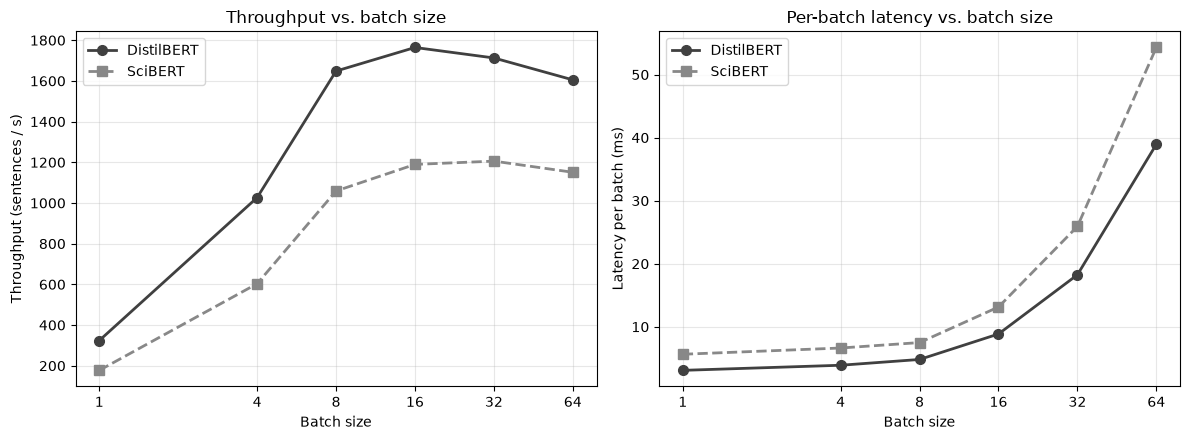

In [17]:
# [RUN] — throughput comparison plot

def plot_throughput_comparison(distil_prof, scibert_prof, batch_sizes):
    """Plot throughput and latency curves for both models side by side.

    Args:
        distil_prof  (dict): Profile results for DistilBERT.
        scibert_prof (dict): Profile results for SciBERT.
        batch_sizes  (list[int]): Tested batch sizes.

    Returns:
        tuple: (fig, axes)
    """
    if not batch_sizes:
        raise ValueError("batch_sizes is empty")
    for name, prof in [("distil_prof", distil_prof), ("scibert_prof", scibert_prof)]:
        missing = [bs for bs in batch_sizes if bs not in prof]
        if missing:
            raise ValueError(f"{name} has no results for batch sizes {missing}")

    panels = [("throughput", "Throughput (sentences / s)", "Throughput vs. batch size"),
              ("latency_ms", "Latency per batch (ms)",     "Per-batch latency vs. batch size")]
    # Same marker, line style and grey as the training-curve plot in 2.5.
    series = [(distil_prof,  "DistilBERT", "o-",  '#404040'),
              (scibert_prof, "SciBERT",    "s--", '#888888')]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, (metric, ylabel, title) in zip(axes, panels):
        for prof, name, style, color in series:
            ax.plot(batch_sizes, [prof[bs][metric] for bs in batch_sizes], style,
                    color=color, linewidth=2, markersize=7, label=name)
        ax.set_xscale("log", base=2)            # batch sizes double, so space them evenly
        ax.set_xticks(batch_sizes, labels=[str(bs) for bs in batch_sizes])
        ax.minorticks_off()
        ax.set_xlabel("Batch size")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    return fig, axes


fig_profile, _ = plot_throughput_comparison(
    distil_profile, scibert_profile, BATCH_SIZES)
plt.show()

### 4.2 — Dynamic vs. fixed padding

In [18]:
def count_fed_tokens(dataloader):
    """Count the input_ids elements the model receives, padding included.

    Args:
        dataloader (DataLoader): Batches exactly as the model sees them.

    Returns:
        int: Sum over batches of batch size x padded length.
    """
    return sum(batch["input_ids"].numel() for batch in dataloader)


def compare_padding_strategies(model, texts, tokenizer, device,
                                batch_size=32, max_length=128):
    """Compare throughput with dynamic vs fixed-length padding.

    Fixed padding: every sequence padded to max_length.
    Dynamic padding: each batch padded to its own longest sequence
                     (DataCollatorWithPadding).

    Args:
        model       (nn.Module):   Fine-tuned model.
        texts       (list[str]):   Input sentences.
        tokenizer:                 Model tokenizer.
        device      (torch.device):  Device to run on.
        batch_size  (int):         Batch size for both strategies.
        max_length  (int):         Fixed padding target length.

    Returns:
        dict: {'fixed_tput': float, 'dynamic_tput': float,
               'fixed_tokens': int, 'dynamic_tokens': int,
               'token_reduction_pct': float}
    """
    # Same collator, batch size and sentence order for both strategies; only
    # the tokenizer padding differs (the collator is a no-op on fixed rows).
    tput, tokens = {}, {}
    for strategy, padding in [("fixed", "max_length"), ("dynamic", False)]:
        dataset = ADETextDataset(texts, tokenizer, max_length, padding=padding)
        loader = make_loader(dataset, tokenizer, batch_size)
        elapsed, _ = time_inference_pass(model, loader, device)
        tput[strategy] = len(dataset) / elapsed
        tokens[strategy] = count_fed_tokens(loader)
    return {
        'fixed_tput':          tput["fixed"],
        'dynamic_tput':        tput["dynamic"],
        'fixed_tokens':        tokens["fixed"],
        'dynamic_tokens':      tokens["dynamic"],
        'token_reduction_pct': 100 * (tokens["fixed"] - tokens["dynamic"]) / tokens["fixed"],
    }


padding_results_distil  = compare_padding_strategies(
    model_distil,  PROFILE_TEXTS, tok_distil,  DEVICE)
padding_results_scibert = compare_padding_strategies(
    model_scibert, PROFILE_TEXTS, tok_scibert, DEVICE)

print(f"{'Strategy':<25} {'DistilBERT tput':>18}  {'SciBERT tput':>14}")
print("-" * 62)
print(f"{'Fixed padding (max_len=128)':<25} "
      f"{padding_results_distil['fixed_tput']:>18.1f}  "
      f"{padding_results_scibert['fixed_tput']:>14.1f}")
print(f"{'Dynamic padding':<25} "
      f"{padding_results_distil['dynamic_tput']:>18.1f}  "
      f"{padding_results_scibert['dynamic_tput']:>14.1f}")
print(f"{'Token reduction':<25} "
      f"{padding_results_distil['token_reduction_pct']:>17.1f}%  "
      f"{padding_results_scibert['token_reduction_pct']:>13.1f}%")

# Named output variables
distilbert_dynamic_tput    = padding_results_distil['dynamic_tput']
scibert_dynamic_tput       = padding_results_scibert['dynamic_tput']
padding_reduction_distil   = padding_results_distil['token_reduction_pct']

Strategy                     DistilBERT tput    SciBERT tput
--------------------------------------------------------------
Fixed padding (max_len=128)             1067.7           649.3
Dynamic padding                       1716.4          1202.2
Token reduction                        38.4%           49.5%


### 4.3 — SLA diagnostic

In [19]:
def check_sla(profile_results, sla_ms=150.0):
    """Determine whether batch_size=1 latency meets a single-document SLA.

    Single-document latency is approximated as latency_ms at batch_size=1,
    since that reflects the worst-case sequential processing scenario.

    Args:
        profile_results (dict): From profile_model — keys are batch sizes.
        sla_ms          (float): Latency SLA in milliseconds.

    Returns:
        dict: {'latency_ms': float, 'meets_sla': bool, 'headroom_ms': float}
              where headroom_ms < 0 means the SLA is missed by that much.
    """
    if 1 not in profile_results:
        raise KeyError("profile_results has no batch_size=1 entry; "
                       "include 1 in BATCH_SIZES to check a single-document SLA")
    if sla_ms <= 0:
        raise ValueError(f"sla_ms must be positive, got {sla_ms}")
    latency_ms = profile_results[1]['latency_ms']
    return {
        'latency_ms':  latency_ms,
        'meets_sla':   bool(latency_ms <= sla_ms),
        'headroom_ms': sla_ms - latency_ms,
    }


SLA_MS = 150.0   # Scenario A SLA

sla_distil  = check_sla(distil_profile,  SLA_MS)
sla_scibert = check_sla(scibert_profile, SLA_MS)

print(f"Single-document SLA check ({SLA_MS:.0f} ms)")
print("=" * 55)
for label, result in [("DistilBERT", sla_distil),
                       ("SciBERT",    sla_scibert)]:
    status = "✓ PASS" if result['meets_sla'] else "✗ FAIL"
    print(f"  {label:<12}  latency={result['latency_ms']:>7.1f}ms  "
          f"headroom={result['headroom_ms']:>+7.1f}ms  {status}")

# Named output variables
distilbert_meets_sla = sla_distil['meets_sla']
scibert_meets_sla    = sla_scibert['meets_sla']

Single-document SLA check (150 ms)
  DistilBERT    latency=    3.1ms  headroom= +146.9ms  ✓ PASS
  SciBERT       latency=    5.6ms  headroom= +144.4ms  ✓ PASS


### 4.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Looking at your throughput curves, describe how throughput scales with batch size for each model. Identify the point (if any) where throughput plateaus and explain the bottleneck responsible. If throughput is still growing at the largest batch size you tested, explain what resource constraint would eventually cause it to stop growing, and how you would confirm this experimentally.

**Question B:** The dynamic padding comparison shows a token reduction percentage. Explain why ADE corpus sentences produce a meaningful reduction (rather than zero). What property of the ADE corpus sentences — compared to, say, a corpus of full clinical notes — makes dynamic padding more or less beneficial here? Under what corpus characteristics would dynamic padding provide almost no speedup?

**Your reflection:**

**A.** Per-batch latency barely moves from batch 1 to 8 (DistilBERT: 3.09 to 4.81 ms), so small batches leave the GPU underutilized and fixed per-batch overhead (Python dispatch, kernel launches, host-to-device copies) dominates. Throughput plateaus once overhead is amortized, at batch 16 for DistilBERT (1764.4 sentences/s) and 16–32 for SciBERT (1189.7, 1205.8), where per-batch latency roughly doubles with batch size (8.86, 18.24, 38.94 ms for DistilBERT), so GPU compute is the bottleneck. Memory is not, since peak allocation grows only 3006.6 − 2746.0 = 260.6 MB from batch 1 to 64 on a 50.9 GB card. The decline to 1605.2 and 1150.9 at batch 64 fits dynamic padding: a larger batch is padded to the longest of more sentences (mean 31.8 DistilBERT tokens, but up to the 128-token cap, Part 5.2), raising pad and attention cost per useful token, which re-profiling with length-bucketed batches would confirm.

**B.** ADE sentences are short against the fixed length of 128 (mean 31.8 DistilBERT and 27.2 SciBERT tokens), so fixed rows are mostly padding; at batch 32 dynamic padding cuts fed tokens by 38.4% and 49.5%, lifting throughput from 1067.7 to 1716.4 and 649.3 to 1202.2 sentences/s. Full clinical notes run far past 128 tokens and are truncated, so almost every row hits the cap, each batch's longest sequence equals the fixed length, and dynamic padding saves almost nothing, as for any corpus whose lengths cluster at max_length.

---

## Part 5 — Supporting checks (ungraded)

These cells run after every graded cell and only read the graded variables and fine-tuned models, so no graded value changes. They print the numbers the reflections quote.

### 5.1 — Architecture of the two fine-tuned models (Parts 1 and 3)

In [20]:
def describe_architecture(model):
    """Model type, parameter count and transformer layer count of a classifier.

    Args:
        model (PreTrainedModel): Fine-tuned Hugging Face sequence classifier.

    Returns:
        tuple[str, int, int]: (model type, parameters, transformer layers).
    """
    config = model.config
    # DistilBertConfig maps num_hidden_layers onto its own n_layers field.
    return (config.model_type, sum(p.numel() for p in model.parameters()),
            config.num_hidden_layers)


print(f"{'Model':<12} {'type':<11} {'parameters':>12} {'layers':>7}")
for name, fine_tuned in [("DistilBERT", model_distil), ("SciBERT", model_scibert)]:
    model_type, n_params, n_layers = describe_architecture(fine_tuned)
    print(f"{name:<12} {model_type:<11} {n_params:>12,} {n_layers:>7}")

Model        type          parameters  layers
DistilBERT   distilbert    66,955,010       6
SciBERT      bert         109,920,002      12


### 5.2 — Token lengths of the profiling sentences (Part 4, Question B)

Lengths of the 500 `PROFILE_TEXTS` under each tokenizer, special tokens included and before truncation. Dynamic padding pads each batch to its longest sentence; fixed padding pads every sentence to 128.

In [21]:
def token_lengths(texts, tokenizer):
    """Tokenized length of each text, special tokens included, without truncation.

    Args:
        texts     (list[str]): Sentences.
        tokenizer:             Hugging Face tokenizer.

    Returns:
        np.ndarray: One length per text.
    """
    return np.array([len(ids) for ids in tokenizer(list(texts))["input_ids"]])


print(f"{'Tokenizer':<12} {'mean':>6} {'median':>7} {'p95':>6} {'max':>5} {'> 128':>6}")
for name, tokenizer in [("DistilBERT", tok_distil), ("SciBERT", tok_scibert)]:
    lengths = token_lengths(PROFILE_TEXTS, tokenizer)
    print(f"{name:<12} {lengths.mean():>6.1f} {np.median(lengths):>7.1f} "
          f"{np.percentile(lengths, 95):>6.1f} {lengths.max():>5d} {(lengths > 128).sum():>6d}")

Tokenizer      mean  median    p95   max  > 128
DistilBERT     31.8    29.0   61.1   137      1
SciBERT        27.2    25.0   52.0   131      1


### 5.3 — Single-document latency on CPU (Scenario A, Part 4.3)

Scenario A serves from CPU-only machines, which 4.3 does not measure when it runs on a GPU. Each fine-tuned model is copied to the CPU (the graded models are not moved) and run with 4 threads: 10 untimed warmup calls, then 100 timed calls that each tokenize and classify one `PROFILE_TEXTS` sentence. A model passes when its p95 latency is within `SLA_MS`.

In [22]:
import copy


def cpu_single_doc_latency(model, texts, tokenizer, n_warmup=10, n_timed=100, n_threads=4):
    """p50 and p95 latency of one-sentence CPU inference on a copy of a model.

    Args:
        model     (nn.Module): Fine-tuned model; a CPU copy is timed, the
                               original is left on its device.
        texts     (list[str]): Sentences; the first n_warmup + n_timed are used.
        tokenizer:             Model tokenizer (tokenization is timed too).
        n_warmup  (int):       Untimed calls before measuring.
        n_timed   (int):       Timed calls.
        n_threads (int):       Torch CPU threads during the run; the previous
                               setting is restored afterwards.

    Returns:
        tuple[float, float]: (p50 ms, p95 ms) over the timed calls.
    """
    if n_timed < 1 or len(texts) < n_warmup + n_timed:
        raise ValueError(f"need n_timed >= 1 and {n_warmup + n_timed} texts, "
                         f"got n_timed={n_timed} and {len(texts)} texts")
    cpu_model = copy.deepcopy(model).to("cpu").eval()
    saved_threads = torch.get_num_threads()
    torch.set_num_threads(n_threads)
    latencies_ms = []
    try:
        with torch.inference_mode():
            for i, text in enumerate(texts[:n_warmup + n_timed]):
                start = time.perf_counter()
                inputs = tokenizer(text, truncation=True, max_length=128,
                                   return_tensors="pt")
                cpu_model(**inputs)
                if i >= n_warmup:
                    latencies_ms.append(1000 * (time.perf_counter() - start))
    finally:
        torch.set_num_threads(saved_threads)
    return float(np.percentile(latencies_ms, 50)), float(np.percentile(latencies_ms, 95))


print(f"CPU, 4 threads, one sentence per call; SLA {SLA_MS:.0f} ms (pass = p95 within SLA)")
for name, fine_tuned, tokenizer in [("DistilBERT", model_distil,  tok_distil),
                                    ("SciBERT",    model_scibert, tok_scibert)]:
    p50, p95 = cpu_single_doc_latency(fine_tuned, PROFILE_TEXTS, tokenizer)
    print(f"  {name:<12} p50={p50:>6.1f} ms  p95={p95:>6.1f} ms  "
          f"{'PASS' if p95 <= SLA_MS else 'FAIL'}")

CPU, 4 threads, one sentence per call; SLA 150 ms (pass = p95 within SLA)


  DistilBERT   p50=  16.5 ms  p95=  25.5 ms  PASS


  SciBERT      p50=  34.0 ms  p95=  48.1 ms  PASS


### 5.4 — Where SciBERT and TF-IDF disagree (Part 2, Question B)

Test sentences the fine-tuned SciBERT classifies correctly and TF-IDF + LR does not, and the reverse. Each group is also counted for negation cues (*no*, *not*, *without*, *absence*/*absent*), against the test-set base rate, because a bag of n-grams cannot scope a negation over a non-adjacent effect term. The shortest examples are printed with their gold label.

In [23]:
import re

NEGATION_CUE = re.compile(r"\b(no|not|without|absence|absent)\b", re.IGNORECASE)

gold = np.asarray(y_test)
scibert_right = np.asarray(scibert_results['predictions']) == gold
tfidf_right   = np.asarray(tfidf_results['predictions']) == gold
scibert_only  = np.flatnonzero(scibert_right & ~tfidf_right)
tfidf_only    = np.flatnonzero(tfidf_right & ~scibert_right)


def with_negation(indices):
    """Return the test-set indices whose sentence contains a negation cue.

    Args:
        indices (Iterable[int]): Positions in X_test.

    Returns:
        list[int]: Indices whose sentence matches NEGATION_CUE.
    """
    return [i for i in indices if NEGATION_CUE.search(X_test[i])]


def shortest(indices, k):
    """Return the k indices whose test sentences are shortest.

    Args:
        indices (Iterable[int]): Positions in X_test.
        k       (int):           Number of indices to return.

    Returns:
        list[int]: Up to k indices, shortest sentence first.
    """
    return sorted(indices, key=lambda idx: len(X_test[idx]))[:k]


print(f"{'Group':<30} {'sentences':>9} {'with negation cue':>18}")
for name, group in [("SciBERT right, TF-IDF wrong", scibert_only),
                    ("TF-IDF right, SciBERT wrong", tfidf_only),
                    ("Both wrong", np.flatnonzero(~scibert_right & ~tfidf_right)),
                    ("All test sentences", np.arange(len(gold)))]:
    print(f"{name:<30} {len(group):>9,} {len(with_negation(group)):>18,}")

print("\nShortest sentences SciBERT gets right and TF-IDF gets wrong:")
for i in shortest(scibert_only, 3):
    print(f"  [{LABEL_NAMES[gold[i]]}] {X_test[i]}")
print("\nShortest of those with a negation cue:")
for i in shortest(with_negation(scibert_only), 2):
    print(f"  [{LABEL_NAMES[gold[i]]}] {X_test[i]}")


Group                          sentences  with negation cue
SciBERT right, TF-IDF wrong          275                 11
TF-IDF right, SciBERT wrong           85                  8
Both wrong                            69                  8
All test sentences                 3,528                277

Shortest sentences SciBERT gets right and TF-IDF gets wrong:
  [ADE] Isotretinoin teratogenicity.
  [Non-ADE] Steroid induced exophthalmos.
  [ADE] Loperamide poisoning in the dog.

Shortest of those with a negation cue:
  [ADE] There is no consensus on the treatment of ticlopidine-induced marrow aplasia.
  [ADE] The occurrence of a myocardial infarction is reported after chemotherapy containing etoposide, in a man with no risk factors for coronary heart disease.


---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (**Runtime → Run all**)
- [x] All four reflections filled in
- [x] Scenario A and B recommendation cells completed
- [x] Named output variables defined:  
  `distilbert_token_count`, `scibert_token_count`,  
  `tfidf_f1`, `tfidf_accuracy`,  
  `distilbert_f1`, `scibert_f1`, `domain_shift_delta`,  
  `scenario_a_recommendation`, `scenario_b_recommendation`,  
  `distilbert_dynamic_tput`, `scibert_dynamic_tput`,  
  `padding_reduction_distil`,  
  `distilbert_meets_sla`, `scibert_meets_sla`
- [x] Every function has a complete docstring
- [x] File saved as `Lab_10.ipynb`